In [ ]:
import numpy as np
import matplotlib.pyplot as plt
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*

In [ ]:
import gdown
gdown.download(id = "1UBB2SpyOQTIb6GWi4fEWEXc_1o81hw75", output = "cellular.npz")

data = np.load("cellular.npz")
mu, u = data['mu'], data['u']

print(mu.shape, u.shape)

Downloading...
From: https://drive.google.com/uc?id=1UBB2SpyOQTIb6GWi4fEWEXc_1o81hw75
To: /content/cellular.npz
100%|██████████| 12.8M/12.8M [00:00<00:00, 101MB/s] 

(200, 1000, 5) (200, 1000, 3)


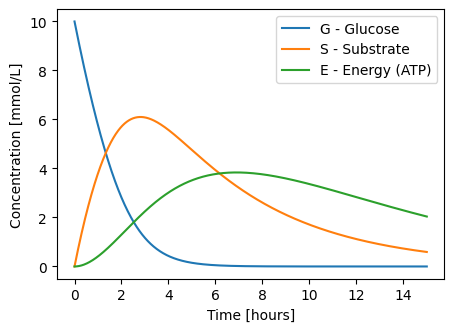

In [ ]:
# Visualization of a random simulation in the dataset
t = np.linspace(0, 15, 1000)
def show(u0):
  G, S, E = u0.T
  plt.figure(figsize = (5, 3.5))
  plt.plot(t, G, label = 'G - Glucose')
  plt.plot(t, S, label = 'S - Substrate')
  plt.plot(t, E, label = 'E - Energy (ATP)')
  plt.xlabel("Time [hours]")
  plt.ylabel("Concentration [mmol/L]")
  plt.legend()

show(u[3])

In [ ]:
#Exercise 1 of the second assignment
# Load precomputed dataset
data = np.load("cellular.npz")
mu, u = data["mu"], data["u"]          # u: (200, 1001, 3) = [G,S,E] over time

# -----------------------------
# Time grid from the statement:
# t_j = j * Δt, j=0,...,1000
# spanning [0, T] with T = 15 h
# -----------------------------
T = 15.0
Nt = u.shape[1]                        # should be 1001
dt = T / (Nt - 1)                      # = 15/1000
time = np.arange(Nt) * dt              # [0, dt, 2dt, ..., T]

print("Nt =", Nt, "| dt =", dt, "hours")
print("time[0], time[-1] =", time[0], time[-1])

# -----------------------------
# Q1 for each of the 200 runs:
# Q1 = (1/4) * ∫_0^4 G(t) dt
# -----------------------------
G = u[:, :, 0]                         # glucose, shape (200, 1001)

mask = (time >= 0.0) & (time <= 4.0)   # first 4 hours
t4 = time[mask]
G4 = G[:, mask]

Q1_samples = np.trapz(G4, t4, axis=1) / 4.0  # shape (200,)

# -----------------------------
# Monte Carlo estimate + 95% CI
# -----------------------------
N = Q1_samples.size
Q1_mean = Q1_samples.mean()
Q1_std  = Q1_samples.std(ddof=1)
half_ci = 1.96 * Q1_std / np.sqrt(N)

print("\nMonte Carlo estimate E[Q1]:", Q1_mean)
print("The difference:", half_ci)
print("95% confidence interval:", (Q1_mean - half_ci, Q1_mean + half_ci))


Nt = 1000 | dt = 0.015015015015015015 hours
time[0], time[-1] = 0.0 15.0

Monte Carlo estimate E[Q1]: 4.087844767431356
The difference: 0.10409445755316785
95% confidence interval: (np.float64(3.9837503098781886), np.float64(4.191939224984524))


/tmp/ipython-input-2770990683.py:29: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  Q1_samples = np.trapz(G4, t4, axis=1) / 4.0  # shape (200,)


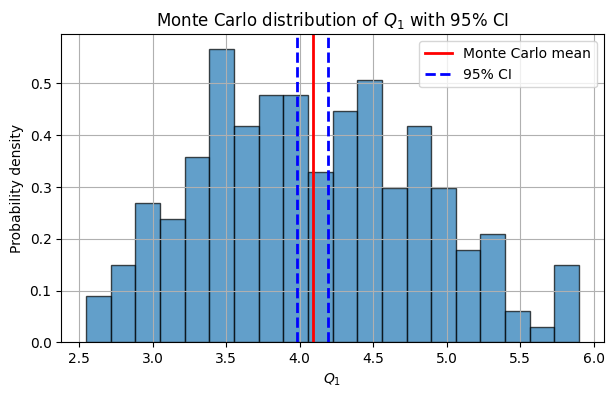

In [ ]:
# Compute CI bounds
lower, upper = Q1_mean - half_ci, Q1_mean + half_ci

plt.figure(figsize=(7,4))
plt.hist(Q1_samples, bins=20, density=True, alpha=0.7, edgecolor='black')

# Mean and CI lines
plt.axvline(Q1_mean, color='red', linewidth=2, label='Monte Carlo mean')
plt.axvline(lower, color='blue', linestyle='--', linewidth=2, label='95% CI')
plt.axvline(upper, color='blue', linestyle='--', linewidth=2)

plt.xlabel(r'$Q_1$')
plt.ylabel('Probability density')
plt.title('Monte Carlo distribution of $Q_1$ with 95% CI')
plt.legend()
plt.grid(True)
plt.show()


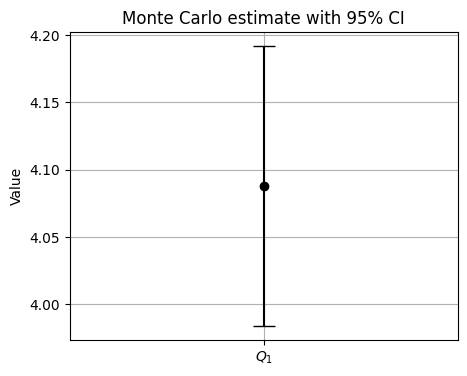

In [ ]:
plt.figure(figsize=(5,4))

plt.errorbar(
    x=0,
    y=Q1_mean,
    yerr=half_ci,
    fmt='o',
    capsize=8,
    color='black'
)

plt.xticks([0], [r'$Q_1$'])
plt.ylabel('Value')
plt.title('Monte Carlo estimate with 95% CI')
plt.grid(True)
plt.show()


### **Doing the same for Q2**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time grid (from the statement)
T = 15.0
Nt = u.shape[1]
dt = T / (Nt - 1)
time = np.arange(Nt) * dt

# Extract variables
G = u[:, :, 0]
S = u[:, :, 1]
E = u[:, :, 2]


In [ ]:
Q2_samples = np.max(E, axis=1)   # shape (200,)


In [ ]:
N = Q2_samples.size
Q2_mean = Q2_samples.mean()
Q2_std  = Q2_samples.std(ddof=1)
half_ci_Q2 = 1.96 * Q2_std / np.sqrt(N)

print("Monte Carlo Estimate E[Q2] =", Q2_mean)
print("95% CI =", (Q2_mean - half_ci_Q2, Q2_mean + half_ci_Q2))


Monte Carlo Estimate E[Q2] = 3.3170245833082377
95% CI = (np.float64(3.179656608269186), np.float64(3.454392558347289))


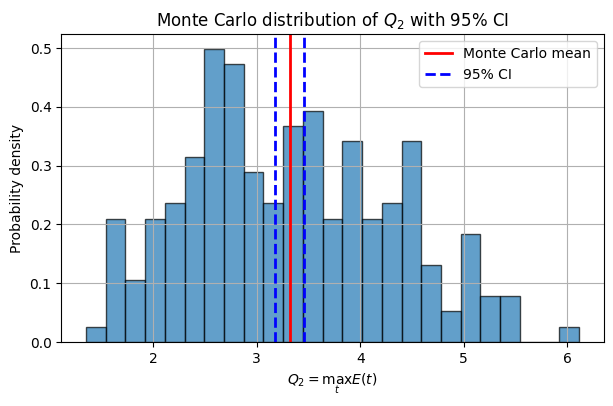

In [ ]:
plt.figure(figsize=(7,4))
plt.hist(Q2_samples, bins=25, density=True, alpha=0.7, edgecolor='black')

plt.axvline(Q2_mean, color='red', linewidth=2, label='Monte Carlo mean')
plt.axvline(Q2_mean - half_ci_Q2, color='blue', linestyle='--', linewidth=2, label='95% CI')
plt.axvline(Q2_mean + half_ci_Q2, color='blue', linestyle='--', linewidth=2)

plt.xlabel(r'$Q_2 = \max_t E(t)$')
plt.ylabel('Probability density')
plt.title('Monte Carlo distribution of $Q_2$ with 95% CI')
plt.legend()
plt.grid(True)
plt.show()


### Using Monte Carlo for Calculating **Q3**

In [ ]:
Q3_samples = np.full(G.shape[0], np.nan)

for i in range(G.shape[0]):

    diff = G[i] - S[i]

    # find first index where sign changes
    j = np.where(diff[:-1] * diff[1:] < 0)[0]

    if j.size > 0:
        j = j[0]
        Q3_samples[i] = time[j]

In [ ]:
Q3_valid = Q3_samples[~np.isnan(Q3_samples)]

N3 = Q3_valid.size
Q3_mean = Q3_valid.mean()
Q3_std  = Q3_valid.std(ddof=1)
half_ci_Q3 = 1.96 * Q3_std / np.sqrt(N3)

print("E[Q3] =", Q3_mean)
print("95% CI =", (Q3_mean - half_ci_Q3, Q3_mean + half_ci_Q3))
print("Valid samples:", N3, "/ 200")


E[Q3] = 1.6762012012012013
95% CI = (np.float64(1.6095609461567704), np.float64(1.7428414562456322))
Valid samples: 200 / 200


In [ ]:
Q3_samples = np.full(G.shape[0], np.nan)

for i in range(G.shape[0]):
    diff = G[i] - S[i]
    sign_change = np.where(diff[:-1] * diff[1:] < 0)[0]

    if len(sign_change) > 0:
        j = sign_change[0]
        # Linear interpolation
        t0, t1 = time[j], time[j+1]
        d0, d1 = diff[j], diff[j+1]
        Q3_samples[i] = t0 - d0 * (t1 - t0) / (d1 - d0)


In [ ]:
Q3_valid = Q3_samples[~np.isnan(Q3_samples)]

N3 = Q3_valid.size
Q3_mean = Q3_valid.mean()
Q3_std  = Q3_valid.std(ddof=1)
half_ci_Q3 = 1.96 * Q3_std / np.sqrt(N3)

print("E[Q3] =", Q3_mean)
print("95% CI =", (Q3_mean - half_ci_Q3, Q3_mean + half_ci_Q3))
print("Valid samples:", N3, "/ 200")


E[Q3] = 1.6839878254941252
95% CI = (np.float64(1.617284635199609), np.float64(1.7506910157886413))
Valid samples: 200 / 200


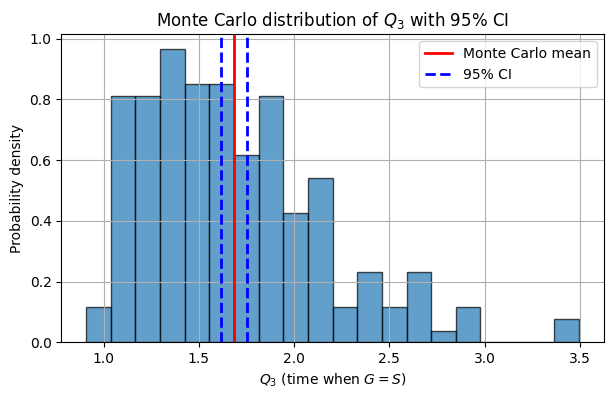

In [ ]:
plt.figure(figsize=(7,4))
plt.hist(Q3_valid, bins=20, density=True, alpha=0.7, edgecolor='black')

plt.axvline(Q3_mean, color='red', linewidth=2, label='Monte Carlo mean')
plt.axvline(Q3_mean - half_ci_Q3, color='blue', linestyle='--', linewidth=2, label='95% CI')
plt.axvline(Q3_mean + half_ci_Q3, color='blue', linestyle='--', linewidth=2)

plt.xlabel(r'$Q_3$ (time when $G=S$)')
plt.ylabel('Probability density')
plt.title('Monte Carlo distribution of $Q_3$ with 95% CI')
plt.legend()
plt.grid(True)
plt.show()


## ***Solution for part (ii) of exercise 3 of the second assignment.***

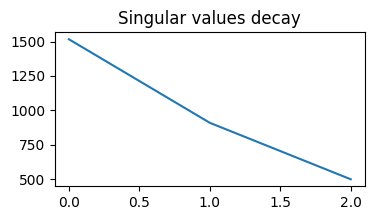

In [ ]:
from scipy.linalg import svd
import matplotlib.pyplot as plt
import numpy as np

ntrain = 150
Nt = u.shape[1]

U = u[:ntrain].reshape(-1, 3).T

X, s, Yt = svd(U, full_matrices=False)

plt.figure(figsize=(4, 2))
plt.plot(s)
plt.title("Singular values decay")
plt.show()

r = 3
V = X[:, :r]

ntrain_snap = ntrain * Nt


In [ ]:
uproj = u @ V @ V.T                  # (200,1000,3)

In [ ]:
# projection
uproj = u @ V @ V.T

# define Euclidean "L2" norm (since no FEM space here)
def l2(x):
    return np.linalg.norm(x, axis=(1,2))

# mean relative error function (same logic as dlroms.mre)
def mre(norm):
    return lambda a, b: np.mean(norm(a - b) / norm(a))

# pretty percentage formatting (like num2p)
def num2p(x):
    return "%.2f%%" % (100*x)

avg_proj_error = mre(l2)(u[ntrain:], uproj[ntrain:])
print("Average projection error: %s." % num2p(avg_proj_error))


Average projection error: 0.00%.


In [ ]:
c = u @ V


In [ ]:
import torch

# (needed earlier) coefficients should be built for ALL simulations
# c = u @ V

# flatten time dimension for ALL simulations (train + test)
#both mu and c have a time dimension, The NN expects a 2D table of input–output pairs, so we flatten
mu_flat = mu.reshape(-1, mu.shape[-1])
c_flat  = c.reshape(-1, c.shape[-1])

# convert to tensors on device (dlroms requirement)
mu_flat, c_flat = dv.tensor(mu_flat, c_flat)

#Define network input/output sizes
p = mu_flat.shape[1]      # 5
n = V.shape[1]            # r

#This constructs a feed-forward network
phi = Dense(p, 30, gelu) + Dense(30, 30, gelu) + Dense(30, n, activation=None)

model = DFNN(phi)
model.He()
model.to(dv)

# number of TRAINING snapshots = 150 simulations * Nt time steps
ntrain_snap = ntrain * u.shape[1]

model.train(mu_flat, c_flat,
            ntrain=ntrain_snap,
            epochs=50,
            loss=mse(euclidean))


		Train		Test
Epoch 50:	1.40e-01	1.44e-01.

>> ETA: 3.04s.


Training complete. Elapsed time: 2 minutes 31.74 seconds.


In [ ]:
model.freeze()

# **Part iii of the exercise**

In [ ]:
M = 10000
p = np.random.uniform([5,5,0.1,0.1], [10,10,0.5,0.5], size=(M,4)) # new parameters

mu_mc = np.zeros((M, Nt, 5))
mu_mc[:,:,:4] = p[:,None,:]
mu_mc[:,:, 4] = t[None,:]

In [ ]:
Z = model(mu_mc)

In [ ]:
import numpy as np
import torch

ntrain = 150
Nt = u.shape[1]
r  = V.shape[1]
t  = mu[0,:, -1]
M  = 10000

def Qs(traj):
    G, S, E = traj[:,0], traj[:,1], traj[:,2]
    Q1 = np.trapz(G[t<=4], t[t<=4]) / 4.0
    Q2 = E.max()
    idx = np.where(G <= S)[0]
    Q3 = t[idx[0]] if idx.size>0 else t[-1]
    return np.array([Q1,Q2,Q3])

#Make sure u and V are NumPy arrays, because Qs() uses NumPy, you convert tensors to NumPy so everything works.
u = u.cpu().numpy() if torch.is_tensor(u) else u
V = V.cpu().numpy() if torch.is_tensor(V) else V

# HF (50 true sims)
#This uses the true ODE solutions from simulations 150–199
Qhf = np.array([Qs(u[i]) for i in range(ntrain, ntrain+50)])

# LF on same 50 (NN -> c -> u)
#
x50 = dv.tensor(mu[ntrain:ntrain+50].reshape(-1,5))
with torch.no_grad():
    c50 = model(x50).cpu().numpy().reshape(50,Nt,r)
Qlf50 = np.array([Qs((c50[i] @ V.T)) for i in range(50)])

# LF Monte Carlo (M=10000)
# Sample 10000 parameters uniformly
p = np.random.uniform([5,5,0.1,0.1],[10,10,0.5,0.5],size=(M,4))
muM = np.zeros((M,Nt,5))
muM[:,:,:4] = p[:,None,:]
muM[:,:, 4] = t[None,:]

# computes surrogate QoIs for all 10000 new samples(Q LF)
xM = dv.tensor(muM.reshape(-1,5))
with torch.no_grad():
    cM = model(xM).cpu().numpy().reshape(M,Nt,r)
QlfM = np.array([Qs((cM[i] @ V.T)) for i in range(M)])

# MF with beta=1
# control variate formulation
Qmf = Qhf.mean(0) - (Qlf50.mean(0) - QlfM.mean(0))
print("Qmf [Q1,Q2,Q3] =", Qmf)


# 95% CI (beta = 1)
EY = QlfM.mean(axis=0)                 # approx E[LF] using M samples
Zcorr = Qhf - (Qlf50 - EY)             # corrected samples (50,3)

CI95 = 1.96 * Zcorr.std(axis=0, ddof=1) / np.sqrt(50)   # half-widths
print("95% CI half-widths =", CI95)



/tmp/ipython-input-174392674.py:12: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  Q1 = np.trapz(G[t<=4], t[t<=4]) / 4.0


Qmf [Q1,Q2,Q3] = [4.05186703 3.41218625 1.66978529]
95% CI half-widths = [0.02411512 0.05141317 0.02825788]


confidence interval in MLF gets tighter because the variance reduces.

Using a GP surrogate is theoretically possible, but practically challenging because:

The dataset becomes extremely large when including time snapshots.

Standard GP training scales cubically in the number of samples.

Multi-output and non-smooth quantities such as
𝑄
3
Q
3
	​

 introduce additional instability.

Large-scale Monte Carlo evaluation becomes computationally expensive.

A practical and robust solution is to fit GPs directly on the quantities of interest, or to use sparse GP techniques.